PREPARACION

In [1]:
import os
os.environ["NIXTLA_ID_AS_COL"] = "true"
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsforecast import StatsForecast
from statsforecast.arima import ndiffs, nsdiffs
from statsforecast.models import ARIMA, AutoARIMA, AutoETS, SeasonalNaive
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.stattools import kpss

warnings.simplefilter("ignore", InterpolationWarning)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (11, 3.8),
                     "figure.constrained_layout.use": True})
AZUL, MARINO, NARANJA = "#0047E9", "#00133F", "#FF9600"

URL_CNMC = ("https://catalogodatos.cnmc.es/dataset/"
            "666f28bb-8177-452a-850c-f8633280de55/resource/"
            "f9304645-19bd-42d1-b4b5-d3b4fffd901d/download/ds_24333_1.csv")
raiz = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists())
DATA = raiz / "data"
SERIES = ["total", "convencional", "electrico"]


def cargar_gas():
    """Demanda diaria de gas (CNMC/Enagás) en formato ancho, GWh/día."""
    ruta = DATA / "ds_24333_1.csv"
    if not ruta.exists():
        DATA.mkdir(exist_ok=True)
        pd.read_csv(URL_CNMC, sep=";",
                    storage_options={"User-Agent": "Mozilla/5.0"}
                    ).to_csv(ruta, sep=";", index=False)
    crudo = pd.read_csv(ruta, sep=";", encoding="utf-8-sig",
                        parse_dates=["Fecha"])
    ancho = (crudo
             .pivot(index="Fecha", columns="tipos de demanda convencional",
                    values="Demanda de gas (MWh)")
             .rename(columns={
                 "Demanda convencional - demanda por gasoducto": "gasoducto",
                 "Demanda convencional - demanda GNL en cisternas": "cisternas",
                 "demanda sector eléctrico": "electrico"})
             .rename_axis(columns=None)
             .div(1_000))                                   # MWh → GWh
    ancho["convencional"] = ancho["gasoducto"] + ancho["cisternas"]
    ancho["total"] = ancho["convencional"] + ancho["electrico"]
    ancho.index.name = "ds"
    return ancho.asfreq("D")


gas = cargar_gas()
mensual = gas[SERIES].resample("MS").sum()                  # GWh/mes
por_dia = mensual.div(mensual.index.days_in_month, axis=0)  # GWh/día
mensual_largo = (por_dia.reset_index()
                 .melt(id_vars="ds", var_name="unique_id", value_name="y")
                 [["unique_id", "ds", "y"]])

H = 12
corte = mensual_largo["ds"].max() - pd.DateOffset(months=H)
train = mensual_largo[mensual_largo["ds"] <= corte]
test = mensual_largo[mensual_largo["ds"] > corte]
print(f"Entrenamiento: {train['ds'].min():%m-%Y} → {train['ds'].max():%m-%Y}")
print(f"Prueba:        {test['ds'].min():%m-%Y} → {test['ds'].max():%m-%Y}")

Entrenamiento: 01-2009 → 03-2025
Prueba:        04-2025 → 03-2026


1 · Estacionariedad: ¿cuántas diferencias?


1.1 · La serie y su periodo estacional

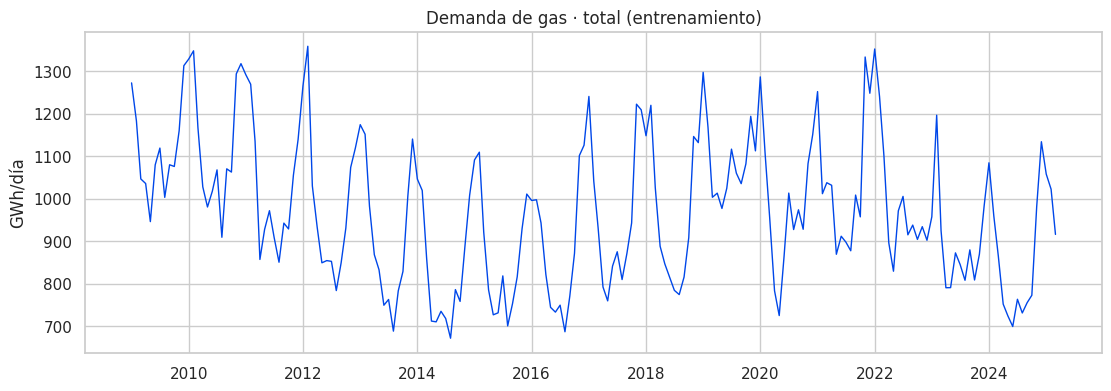

In [2]:
M = 12              # periodo estacional: los datos son mensuales
MI_SERIE = "total"   # la serie de los bloques 1 a 3
serie = train.query("unique_id == @MI_SERIE")
y = serie["y"].to_numpy()

fig, ax = plt.subplots()
ax.plot(serie["ds"], serie["y"], color=AZUL, lw=1)
ax.set(title=f"Demanda de gas · {MI_SERIE} (entrenamiento)", ylabel="GWh/día")
plt.show()

1.2 · ¿Cuántas diferencias pide?

In [3]:
d = ndiffs(y)                       # diferencias ordinarias (test KPSS)
D = nsdiffs(y, period=M)             # diferencias estacionales
print(f"{MI_SERIE}: d = {d}, D = {D}")

total: d = 0, D = 1


1.3 · Aplicar las diferencias y comprobar

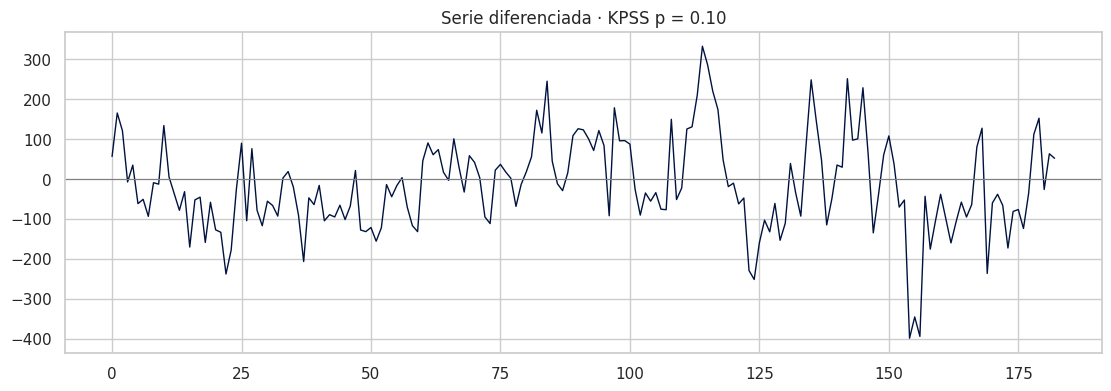

In [4]:
z = pd.Series(y)
for _ in range(D):
    z = z.diff(12)              # diferencia estacional: y(t) - y(t-12)
for _ in range(d):
    z = z.diff()                 # diferencia ordinaria: y(t) - y(t-1)
z = z.dropna()

p_kpss = kpss(z, nlags="auto")[1]
fig, ax = plt.subplots()
ax.plot(z.to_numpy(), color=MARINO, lw=1)
ax.axhline(0, color="grey", lw=0.8)
ax.set(title=f"Serie diferenciada · KPSS p = {p_kpss:.2f}")
plt.show()

1.4 · ¿Y las otras dos series?

In [5]:
tabla_dD = {}
for s_ in SERIES:
    ys = train.query("unique_id == @s_")["y"].to_numpy()
    tabla_dD[s_] = {"d": ndiffs(ys), "D": nsdiffs(ys, period=M)}
pd.DataFrame(tabla_dD).T

,d,D
total,0,1
convencional,0,1
electrico,1,0


CP1 · Estacionariedad
La serie total pide d = 0 y D = 1: con una diferencia estacional basta para quitar el ciclo anual. Después de diferenciar, el KPSS da p = 0,10, mayor que 0,05, así que la serie ya es estacionaria. La convencional pide lo mismo, pero la eléctrica pide d = 1 y D = 0, porque depende más del mix de generación que del calendario. Por eso será la más difícil de prever.

2 · Identificar: ¿qué memoria tiene?



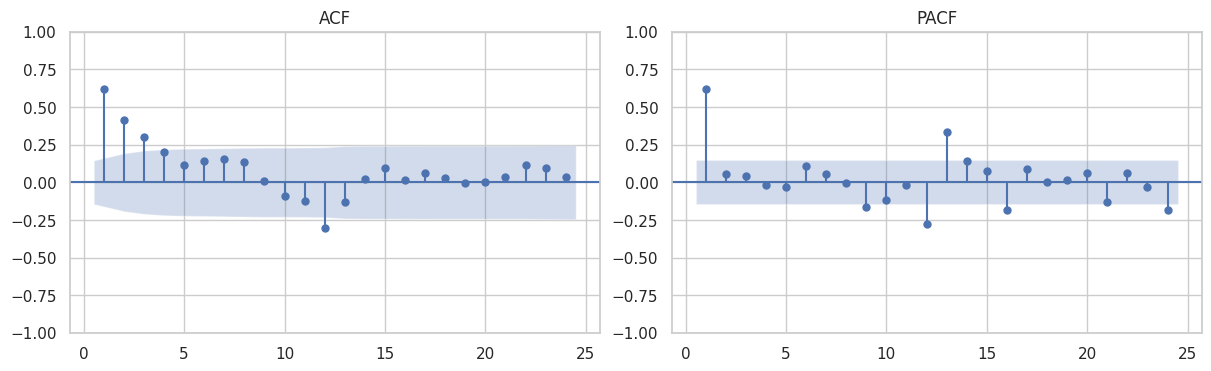

In [6]:
RETARDOS = 24                   # dos años: se ven los retardos 12 y 24
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
plot_acf(z, lags=RETARDOS, ax=ax[0], zero=False)
plot_pacf(z, lags=RETARDOS, ax=ax[1], zero=False, method="ywm")
ax[0].set_title("ACF"); ax[1].set_title("PACF")
plt.show()

CP2 · Identificar
La ACF baja poco a poco y la PACF se corta en el retardo 1, así que propongo un AR(1): p = 1, q = 0. En el retardo 12 la ACF tiene un pico negativo que desaparece en el 24, lo que indica un MA estacional: P = 0, Q = 1. Mi propuesta es ARIMA(1,0,0)(0,1,1)[12].

 3 · Estimar y comprobar

3.1 · Candidatos y AICc



In [7]:
p, q = 1, 0                  # tu propuesta de CP2 (parte no estacional)
P, Q = 0, 1                  # tu propuesta de CP2 (parte estacional)

In [8]:
def etiqueta(ajustado):
    """ARIMA(p,d,q)(P,D,Q)[m] a partir del modelo ajustado."""
    pp, qq, PP, QQ, m, dd, DD = ajustado.model_["arma"]
    return f"ARIMA({pp},{dd},{qq})({PP},{DD},{QQ})[{m}]"


candidatos = {
    "sin memoria": ARIMA(order=(0, d, 0), seasonal_order=(0, D, 0),
                         season_length=M),
    "tu propuesta": ARIMA(order=(p, d, q), seasonal_order=(P, D, Q),
                          season_length=M),
    "AutoARIMA": AutoARIMA(season_length=M),
}
filas = []
for nombre, modelo in candidatos.items():
    ajustado = modelo.fit(y)
    filas.append({"candidato": nombre, "modelo": etiqueta(ajustado),
                  "AICc": ajustado.model_["aicc"]})
pd.DataFrame(filas).sort_values("AICc").round(1).reset_index(drop=True)

,candidato,modelo,AICc
0,AutoARIMA,"ARIMA(1,0,1)(0,1,1)[12]",2104.2
1,tu propuesta,"ARIMA(1,0,0)(0,1,1)[12]",2113.4
2,sin memoria,"ARIMA(0,0,0)(0,1,0)[12]",2267.2


CP3 · Elegir
El mejor AICc es el de AutoARIMA (2104,2), que elige ARIMA(1,0,1)(0,1,1)[12]. Es casi mi modelo con un MA(1) más, y el mío queda cerca (2113,4). Los dos mejoran mucho al modelo sin memoria (2267,2). No se puede comparar el AICc con distinta d porque cada modelo se ajusta a una serie distinta.

4 · Residuos


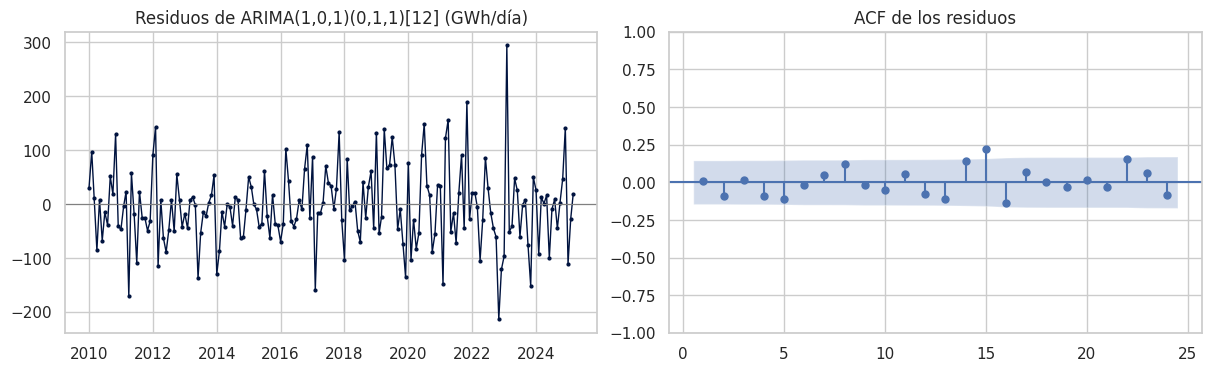

Ljung-Box (24 retardos): p = 0.008


In [9]:
auto = AutoARIMA(season_length=M).fit(y)
res = auto.model_["residuals"][M:]
pp, qq, PP, QQ = auto.model_["arma"][:4]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(serie["ds"].iloc[M:], res, color=MARINO, lw=1, marker="o", ms=2)
ax[0].axhline(0, color="grey", lw=0.8)
ax[0].set_title(f"Residuos de {etiqueta(auto)} (GWh/día)")
plot_acf(res, lags=24, ax=ax[1], zero=False)
ax[1].set_title("ACF de los residuos")
plt.show()

lb = acorr_ljungbox(res, lags=[24], model_df=pp + qq + PP + QQ)
print(f"Ljung-Box (24 retardos): p = {lb['lb_pvalue'].iloc[0]:.3f}")

CP4 · Residuos
Ljung-Box da p = 0,008, menor que 0,05, así que los residuos no son ruido blanco: queda información que el modelo no recoge, como se ve en los retardos 15 y 22 de la ACF. Habría que probar más términos o añadir variables como la temperatura. La predicción sirve, pero los intervalos de confianza son demasiado optimistas.

4 · Evaluar contra el listón


In [10]:
MODELOS = ["SeasonalNaive", "AutoETS", "AutoARIMA"]
sf = StatsForecast(models=[SeasonalNaive(season_length=M),
                           AutoETS(season_length=M),
                           AutoARIMA(season_length=M)],
                   freq="MS")
pred = sf.forecast(df=train, h=H)        # solo entrenamiento: sin fuga de información

cruce = test.merge(pred, on=["unique_id", "ds"])
error = pd.DataFrame({
    serie_: {m: np.abs(g["y"] - g[m]).mean() for m in MODELOS}
    for serie_, g in cruce.groupby("unique_id")}).T.loc[SERIES]
error["mejor"] = error[MODELOS].idxmin(axis=1)
error["mejora vs SN %"] = (1 - error[MODELOS].min(axis=1)
                           / error["SeasonalNaive"]) * 100
error.round(1)

,SeasonalNaive,AutoETS,AutoARIMA,mejor,mejora vs SN %
total,62.4,54.3,46.0,AutoARIMA,26.3
convencional,27.7,29.6,26.4,AutoARIMA,4.5
electrico,73.0,38.6,65.4,AutoETS,47.1


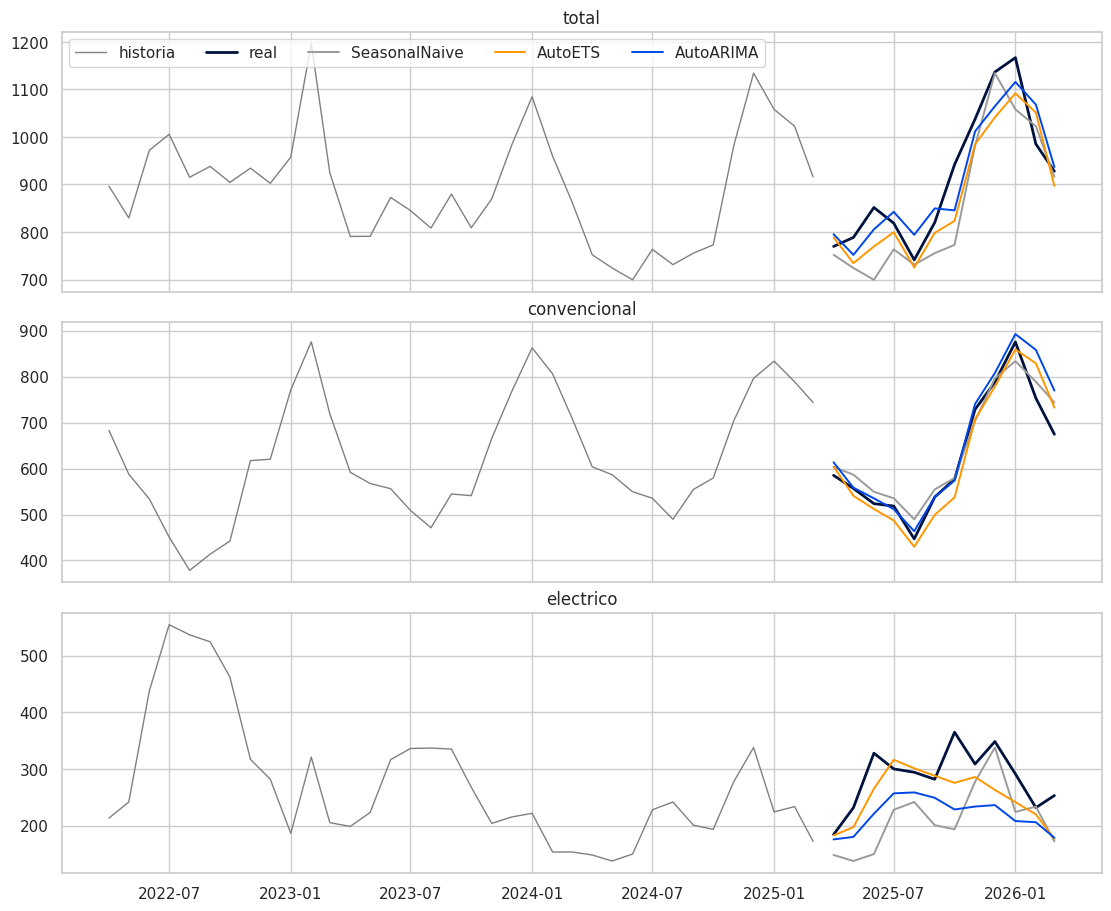

In [11]:
fig, ejes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, s in zip(ejes, SERIES):
    hist = train[train["unique_id"] == s].tail(36)
    ax.plot(hist["ds"], hist["y"], color="grey", lw=1, label="historia")
    real = test[test["unique_id"] == s]
    ax.plot(real["ds"], real["y"], color=MARINO, lw=2, label="real")
    for m, c in zip(MODELOS, ["#9A9A9A", NARANJA, AZUL]):
        p_ = pred[pred["unique_id"] == s]
        ax.plot(p_["ds"], p_[m], color=c, lw=1.4, label=m)
    ax.set_title(s)
ejes[0].legend(ncol=5, loc="upper left")
plt.show()

CP5 · Veredicto
En total gana AutoARIMA (−26 % de error frente al seasonal naïve), en convencional también, pero mejora muy poco (−4,5 %), y en eléctrico gana ETS (−47 %). No gana el mismo modelo en todas las series, así que con una sola partición el ganador podría cambiar si probáramos otro año.

5 · Predecir y recomendar (en casa)
5.1 · El invierno 2026/27 con el modelo ganador


In [12]:
sf_f = StatsForecast(models=[SeasonalNaive(season_length=M),
                             AutoETS(season_length=M),
                             AutoARIMA(season_length=M)], freq="MS")
futuro = sf_f.forecast(df=mensual_largo, h=12)    # toda la historia, hasta marzo de 2026
dias = futuro["ds"].dt.days_in_month
for m in MODELOS:
    futuro[m] = futuro[m] * dias / 1_000          # GWh/día → TWh/mes
ganador = error["mejor"]                          # ganador por serie (bloque 4)
futuro["ganador"] = [fila[ganador[fila["unique_id"]]]
                     for _, fila in futuro.iterrows()]

invierno = futuro[futuro["ds"] >= "2026-10-01"]
inv_twh = invierno.groupby("unique_id")[["SeasonalNaive", "ganador"]].sum()
inv_twh = inv_twh.loc[SERIES].assign(modelo=ganador)
inv_twh["cambio vs parte 1 %"] = (inv_twh["ganador"]
                                  / inv_twh["SeasonalNaive"] - 1) * 100
inv_twh.round(1)

,SeasonalNaive,ganador,modelo,cambio vs parte 1 %
unique_id,,,,
total,188.1,185.8,AutoARIMA,-1.2
convencional,133.3,135.2,AutoARIMA,1.4
electrico,54.8,57.4,AutoETS,4.7


Mes a mes, en TWh, con el ganador de cada serie:

In [13]:
mes = invierno.pivot(index="ds", columns="unique_id", values="ganador")[SERIES]
mes.index = mes.index.strftime("%b-%Y")
mes.round(1)

unique_id,total,convencional,electrico
ds,,,
Oct-2026,27.0,17.0,11.2
Nov-2026,30.9,21.4,11.1
Dec-2026,33.6,24.2,10.7
Jan-2027,35.2,26.9,9.6
Feb-2027,29.9,22.9,7.7
Mar-2027,29.1,22.8,7.1


5.2 · Contraste con Enagás (abril–agosto de 2026)

Los cinco primeros meses predichos ya han ocurrido. Enagás los publica en su
*Progreso mensual de la demanda* (TWh, un decimal, provisionales): son los
mismos avances que usaste en la parte 1. ¿Se habría equivocado menos el
ganador que tu *seasonal naïve*?

In [14]:
enagas = pd.DataFrame({                           # TWh, Progreso_<mes>26.pdf
    "ds": pd.date_range("2026-04-01", periods=5, freq="MS"),
    "total":        [23.1, 24.2, 23.8, 27.5, 25.1],
    "convencional": [16.4, 17.0, 15.3, 15.3, 13.1],
    "electrico":    [6.6, 7.2, 8.6, 12.2, 12.0],
}).melt(id_vars="ds", var_name="unique_id", value_name="real")

contraste = enagas.merge(futuro, on=["unique_id", "ds"])
resumen = contraste.groupby("unique_id")[["real", "SeasonalNaive",
                                          "ganador"]].sum().loc[SERIES]
for m, col in [("SeasonalNaive", "error SN %"), ("ganador", "error ganador %")]:
    resumen[col] = (resumen[m] / resumen["real"] - 1) * 100
resumen.round(1)

,real,SeasonalNaive,ganador,error SN %,error ganador %
unique_id,,,,,
total,123.7,121.4,123.4,-1.8,-0.2
convencional,77.1,80.5,76.2,4.4,-1.2
electrico,46.6,41.0,49.7,-12.0,6.6
